# Reverse Proxy Benchmark Visualization

Analysis of performance benchmarks across different optimization stages and configurations.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

# Set style
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (14, 6)

In [3]:
# Read JSONL file
file_path = Path('../bench/results.jsonl')  # ponytail: adjust path as needed

data = []
with open(file_path) as f:
    for line in f:
        data.append(json.loads(line))

df = pd.DataFrame(data)
print(f"Loaded {len(df)} benchmark records")
print(f"\nDataframe shape: {df.shape}")
print(f"\nFirst row:")
print(df.iloc[0])

Loaded 264 benchmark records

Dataframe shape: (264, 14)

First row:
timestamp      2026-08-07T18:27:35
stage              00-no-keepalive
kind                 reverse_proxy
mode                         close
commit                     e9a9b77
concurrency                     10
wrk_threads                      4
duration                       10s
repeat                           1
req_per_sec               15237.27
p50_ms                         NaN
p75_ms                        1.19
p90_ms                        2.75
p99_ms                        4.55
Name: 0, dtype: object


In [4]:
# Data overview
print(f"Stages: {sorted(df['stage'].unique())}")
print(f"Modes: {df['mode'].unique()}")
print(f"Concurrency levels: {sorted(df['concurrency'].unique())}")
print(f"Commits: {df['commit'].unique()}")

Stages: ['00-no-keepalive', '01-client-only', '02-backend-only', '03-both', '04-chunked', '05-pool-16', '06-pool-4', '07-epoll-no-keepalive', '08-epoll-client-only', '09-epoll-backend-only', '10-epoll-both', '11-epoll-chunked', '12-epoll-pool-100', '13-epoll-pool-4', '14-epoll-loops-4', '15-io-uring', '16-epoll-loops-2', '17-epoll-loops-8', '18-io-uring-no-keepalive', '19-io-uring-client-only', '20-io-uring-entries-1024', '21-io-uring-entries-16384']
Modes: <StringArray>
['close', 'open']
Length: 2, dtype: str
Concurrency levels: [np.int64(10), np.int64(50), np.int64(100), np.int64(200), np.int64(500), np.int64(1000)]
Commits: <StringArray>
['e9a9b77', 'a2adb2e', 'f4d42cc']
Length: 3, dtype: str


In [5]:
# Clean up: replace null latencies with NaN for proper plotting
for col in ['p50_ms', 'p75_ms', 'p90_ms', 'p99_ms']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Data prepared.")

Data prepared.


## Throughput (requests/sec) vs Concurrency by Stage

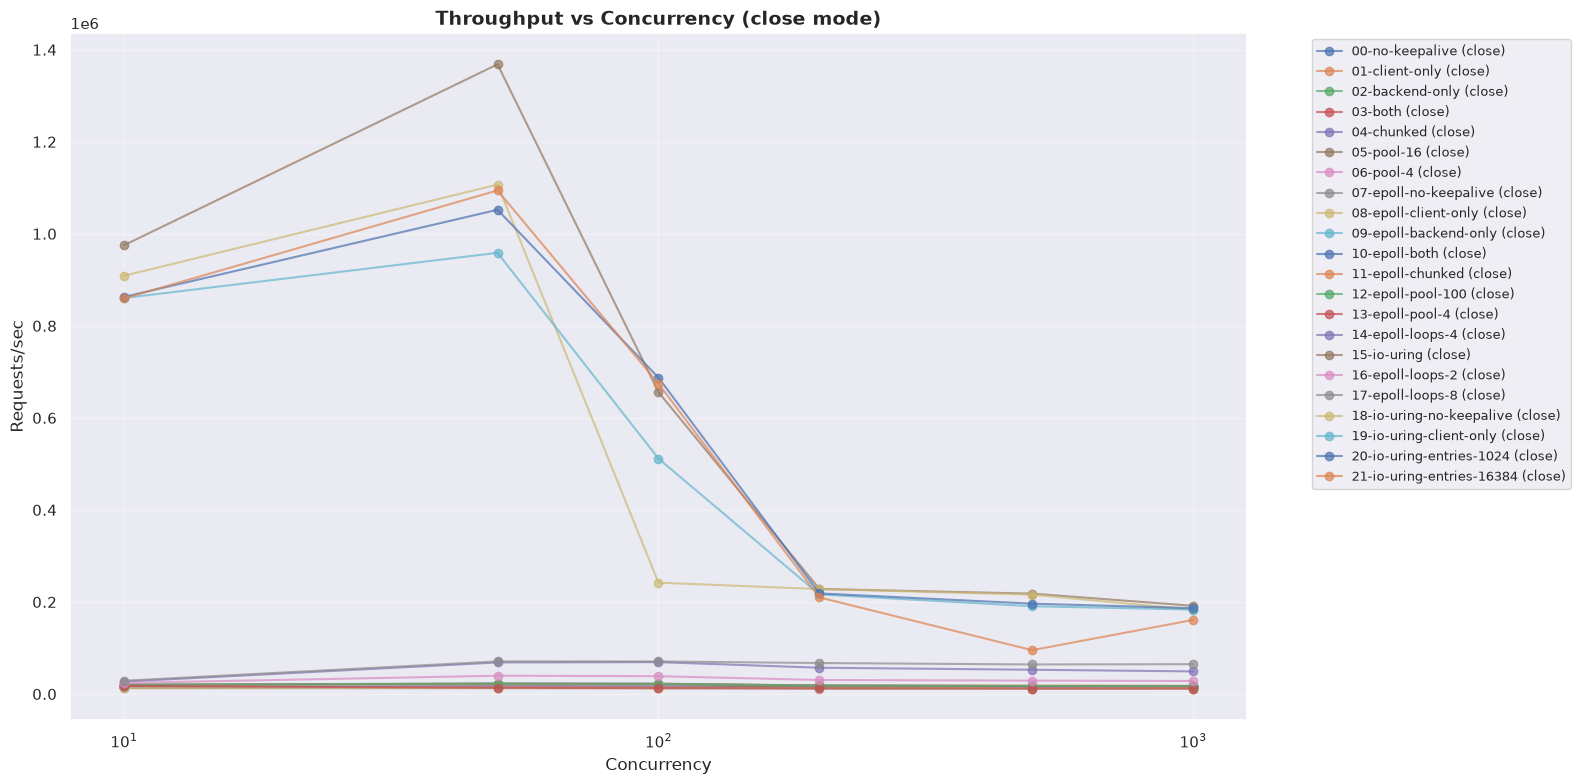

In [6]:
fig, ax = plt.subplots(figsize=(16, 8))

# Plot close mode
close_data = df[df['mode'] == 'close'].sort_values('concurrency')
for stage in sorted(close_data['stage'].unique()):
    stage_df = close_data[close_data['stage'] == stage]
    ax.plot(stage_df['concurrency'], stage_df['req_per_sec'], 
            marker='o', label=f'{stage} (close)', alpha=0.7)

ax.set_xlabel('Concurrency', fontsize=12)
ax.set_ylabel('Requests/sec', fontsize=12)
ax.set_title('Throughput vs Concurrency (close mode)', fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Throughput Comparison: close vs open modes

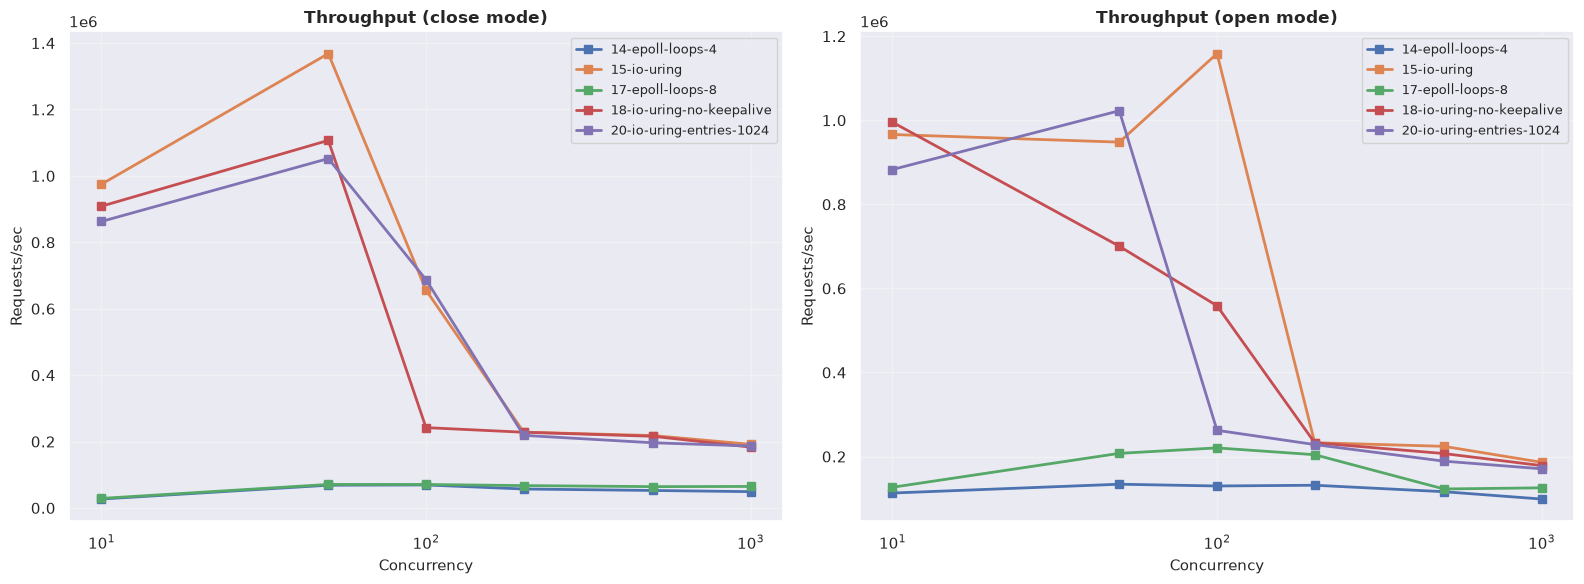

In [7]:
# ponytail: filter to recent stages with meaningful differences
recent_stages = ['14-epoll-loops-4', '15-io-uring', '17-epoll-loops-8', '18-io-uring-no-keepalive', '20-io-uring-entries-1024']
subset = df[df['stage'].isin(recent_stages)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for mode, ax in zip(['close', 'open'], axes):
    mode_df = subset[subset['mode'] == mode].sort_values('concurrency')
    for stage in sorted(mode_df['stage'].unique()):
        stage_df = mode_df[mode_df['stage'] == stage]
        ax.plot(stage_df['concurrency'], stage_df['req_per_sec'], 
                marker='s', label=stage, linewidth=2)
    
    ax.set_xlabel('Concurrency', fontsize=11)
    ax.set_ylabel('Requests/sec', fontsize=11)
    ax.set_title(f'Throughput ({mode} mode)', fontsize=12, fontweight='bold')
    ax.set_xscale('log')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## P99 Latency vs Concurrency

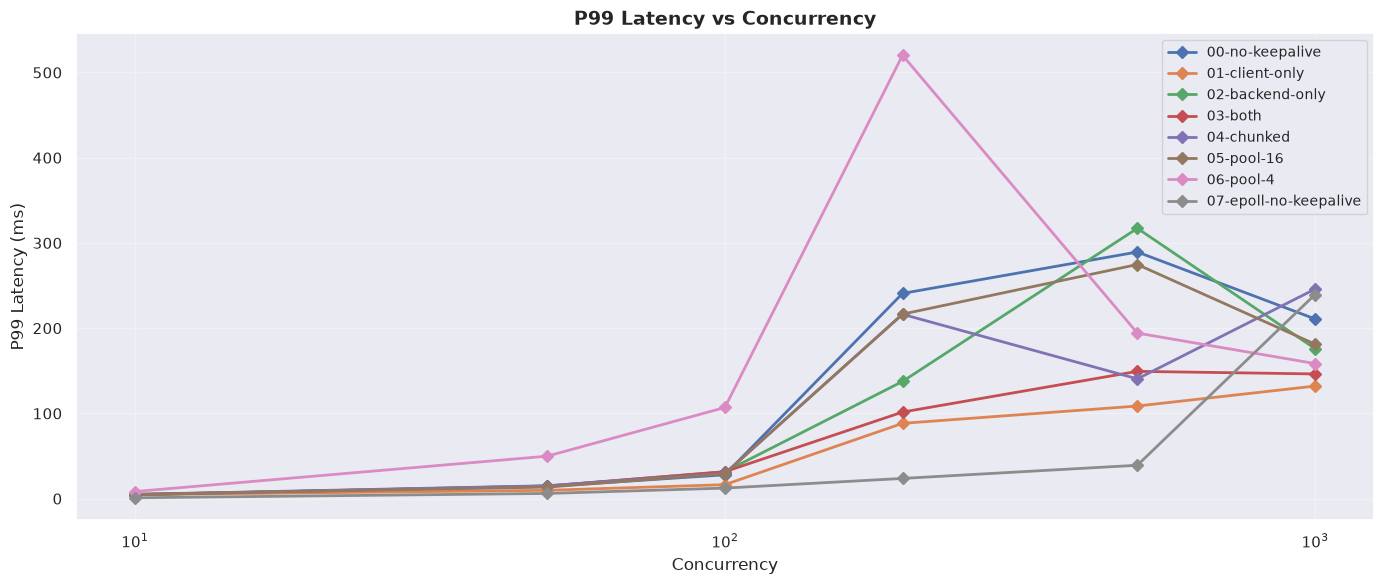

In [8]:
fig, ax = plt.subplots(figsize=(14, 6))

# Focus on stages with complete p99 data
latency_data = df[df['p99_ms'].notna()].sort_values('concurrency')

for stage in sorted(latency_data['stage'].unique())[:8]:  # ponytail: limit to first 8 for readability
    stage_df = latency_data[latency_data['stage'] == stage]
    # Average across close/open modes
    avg_latency = stage_df.groupby('concurrency')['p99_ms'].mean()
    ax.plot(avg_latency.index, avg_latency.values, 
            marker='D', label=stage, linewidth=2)

ax.set_xlabel('Concurrency', fontsize=12)
ax.set_ylabel('P99 Latency (ms)', fontsize=12)
ax.set_title('P99 Latency vs Concurrency', fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary Stats by Stage (close mode at concurrency=50)

In [9]:
summary = df[(df['mode'] == 'close') & (df['concurrency'] == 50)][['stage', 'req_per_sec', 'p50_ms', 'p99_ms']].copy()
summary = summary.sort_values('req_per_sec', ascending=False)
print(summary.to_string(index=False))

                    stage  req_per_sec  p50_ms  p99_ms
              15-io-uring   1368239.51   0.084   0.369
 18-io-uring-no-keepalive   1106914.76   0.097   0.339
21-io-uring-entries-16384   1094281.60   0.096   0.342
 20-io-uring-entries-1024   1052182.00   0.110   0.349
  19-io-uring-client-only    958678.70   0.118   0.307
         17-epoll-loops-8     70844.74   0.269   1.210
         14-epoll-loops-4     68520.22   0.396   1.970
         16-epoll-loops-2     39728.34   1.050   2.650
            10-epoll-both     22762.03   1.980   3.080
         11-epoll-chunked     22450.41   1.990   3.490
        12-epoll-pool-100     22370.37   1.980   3.940
    09-epoll-backend-only     22038.04   2.000   4.250
               04-chunked     16118.64   1.450  15.170
          00-no-keepalive     15970.98   1.550  14.550
                  03-both     15882.52   1.720  14.720
               05-pool-16     15656.36   1.990  13.560
          02-backend-only     15587.06   1.980  14.380
          

## Performance Delta: open vs close mode

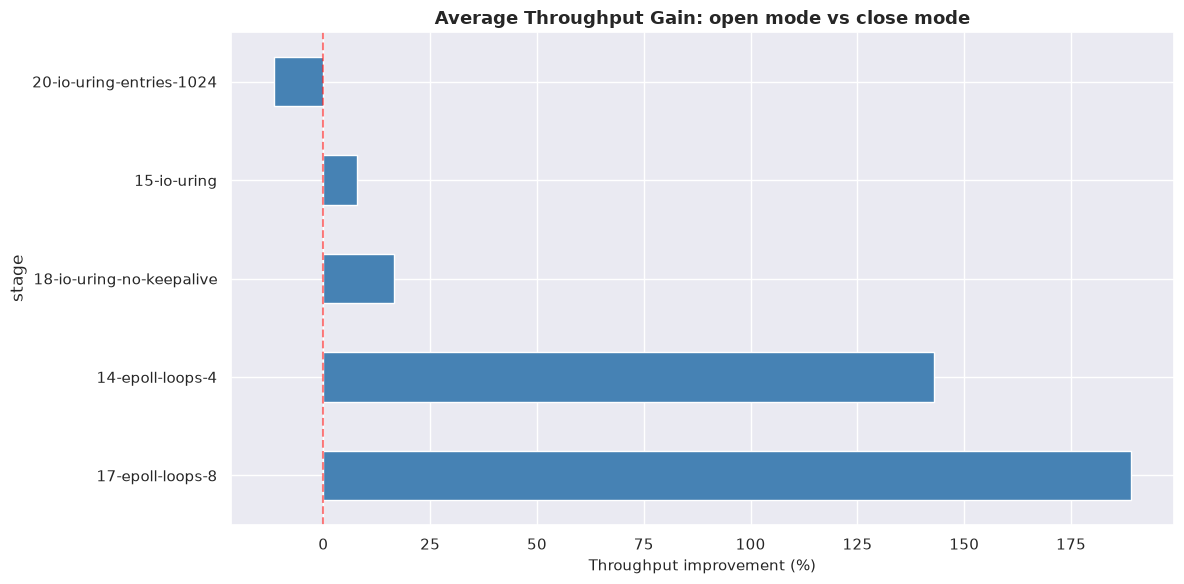


Improvement summary:
stage
17-epoll-loops-8            189.050000
14-epoll-loops-4            142.833333
18-io-uring-no-keepalive     16.516667
15-io-uring                   7.833333
20-io-uring-entries-1024    -11.650000
Name: improvement_pct, dtype: float64


In [10]:
# Calculate throughput improvement when using open mode
pivot = df[df['stage'].isin(recent_stages)].pivot_table(
    values='req_per_sec', 
    index=['stage', 'concurrency'], 
    columns='mode'
)
pivot['improvement_pct'] = ((pivot['open'] - pivot['close']) / pivot['close'] * 100).round(1)

fig, ax = plt.subplots(figsize=(12, 6))
improvement_by_stage = pivot.groupby('stage')['improvement_pct'].mean().sort_values(ascending=False)
improvement_by_stage.plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Throughput improvement (%)', fontsize=11)
ax.set_title('Average Throughput Gain: open mode vs close mode', fontsize=13, fontweight='bold')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\nImprovement summary:")
print(improvement_by_stage)

## Latency Distribution at High Concurrency (1000)

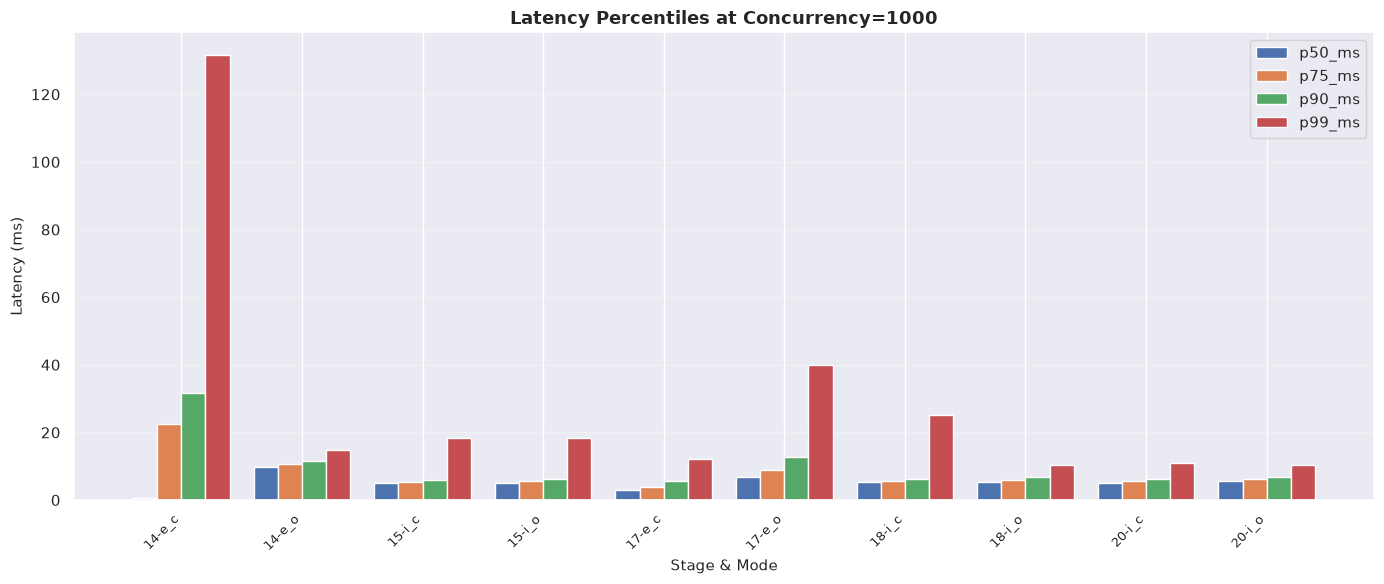

In [11]:
high_conc = df[(df['concurrency'] == 1000) & (df['stage'].isin(recent_stages))]

fig, ax = plt.subplots(figsize=(14, 6))
latency_cols = ['p50_ms', 'p75_ms', 'p90_ms', 'p99_ms']

# Group by stage and mode, average the latencies
grouped = high_conc.groupby(['stage', 'mode'])[latency_cols].mean().reset_index()

x = range(len(grouped))
width = 0.2
for i, col in enumerate(latency_cols):
    ax.bar([p + i*width for p in x], grouped[col], width, label=col)

ax.set_xlabel('Stage & Mode', fontsize=11)
ax.set_ylabel('Latency (ms)', fontsize=11)
ax.set_title('Latency Percentiles at Concurrency=1000', fontsize=13, fontweight='bold')
ax.set_xticks([p + width*1.5 for p in x])
ax.set_xticklabels([f"{r['stage'][:4]}_{r['mode'][0]}" for _, r in grouped.iterrows()], 
                    rotation=45, ha='right', fontsize=9)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()